# Radiografía Laboral
### Lo que no se ve del absentismo por salud en España: quién falta, por qué, dónde y cómo actuar antes

Cada vez hay más bajas médicas (9,2 millones por enfermedad común en 2025, un 12,8 % más que en 2023) y 1 de cada 4 trabajadores falta al trabajo por salud cada año. Pero la mitad de todos los días de ausencia se concentra en solo el **1,6 %** de los trabajadores, con un perfil muy claro: problemas **musculoesqueléticos y de salud mental**. Hoy se actúa cuando la baja ya es larga. 
La radiografía nos muestra el camino para actuar antes.

Esta memoria resume el proyecto. El trabajo completo, paso a paso, está en el notebook `EDA_laboral.ipynb`.

---
## 1. Por qué este proyecto

Soy Terapeuta Ocupacional. A tratamiento me llegaban las personas cuando ya llevaban meses de baja o cuando ya habían recaído: veía el problema cuando ya estaba muy avanzado, pero no lo que había detrás. Me preguntaba si eso era solo mi experiencia o si ocurre de verdad.

Las bajas costaron unos **18.413 millones de euros** en 2025. Esa factura la pagan **mutuas, aseguradoras y empresas** (recursos humanos): es interesante conocer dónde, en quién y por qué se concentra el absentismo para poder actuar antes.

**La pregunta:** ¿quién falta al trabajo por salud, por qué y dónde? ¿Se concentra en pocas personas? ¿Cuánto se podría ahorrar actuando antes?

## 2. Lo que pensaba encontrar (hipótesis)

Antes de analizar los datos, me planteaba si:

- Cada vez hay más bajas 
- Hay diferencias entre comunidades y entre sectores
- Los sobreesfuerzos son la primera causa de los accidentes con baja 
- Los problemas de espalda y de salud mental hacen faltar más
- Unos pocos trabajadores se llevan la mayoría de los días de ausencia 
- Las distintas fuentes reflejan lo mismo por comunidad 

---
## 3. Los datos

Utilizo **cuatro fuentes oficiales**, todas de España. Cada una responde a una parte de la pregunta:

| Fuente | Qué me dice | Datos | Tipo |
|---|---|---|---|
| **INE**, tabla 6063 (Encuesta Trimestral de Coste Laboral) | **Dónde y cuándo:** horas no trabajadas por comunidad, sector y trimestre, de 2008 a 2026 | CSV | Agregados |
| **Seguridad Social**, Estadística de Incapacidad Temporal 2023-2025 | **Cuántas bajas:** bajas médicas por provincia, cuántas empiezan, cuánto duran y cuántas siguen abiertas | Excel | Registros agregados |
| **Ministerio de Trabajo**, Accidentes de Trabajo 2025 | **Por qué:** cómo se produjeron 546.473 accidentes con baja y cuántos recayeron, por sector | Excel | Agregados |
| **Ministerio de Sanidad**, Encuesta de Salud de España 2023 | **Quién:** si cada persona faltó por salud, cuántos días y qué problemas de salud tiene | Microdatos (.tab) | Una fila por persona |

**Cantidad:** entre las cuatro fuentes hay unas **187.000 filas** y más de **12 millones de datos**.

- **Son reales:** datos oficiales, no inventados ni sintéticos.
- **Son anónimos:** la encuesta no tiene nombres ni nada que identifique a nadie, y el resto son totales.
- **Son de España:** al comparar comunidades hay que tener en cuenta que cada una tiene su tejido productivo y su cultura del trabajo.

**Tipos de variables:** las **categóricas** dicen a qué grupo pertenece algo (comunidad, sector, sexo, tener o no un problema de salud) y se resumen con frecuencias y porcentajes. Las **numéricas continuas** (horas, tasas, el factor de elevación) y las **numéricas discretas** que se cuentan (accidentes, días de baja, edad) se resumen con media, mediana y desviación.

## 4. Cómo he limpiado los datos

La limpieza completa está en el notebook `EDA_laboral.ipynb`. Aquí, el resumen:

| Fuente | Cómo venía | Qué he hecho |
|---|---|---|
| **INE** | Formato con todas las categorías, coma en el decimal y periodo como texto | Me quedo con las filas que necesito, renombro, paso `Total` a número, saco el código de comunidad, creo la fecha y calculo la **tasa de horas no trabajadas** (horas no trabajadas / horas pactadas × 100) |
| **Accidentes** | Hoja de Excel pensada para imprimir, con títulos y totales | Busco la cabecera, me quedo con los 4 sectores, paso de formato ancho a largo con `melt`, quito «Sin información» y compruebo que el total cuadra con el oficial (546.473) |
| **Recaídas** | Hoja de Excel para imprimir | Me quedo con los 4 sectores y calculo la tasa de recaída por cada 100 accidentes |
| **Encuesta de Salud** | 21.032 adultos y 432 columnas de códigos | Uno adultos y hogar con `merge` (y lo compruebo con una **query SQL**), me quedo con los **9.875 ocupados**, traduzco los códigos, trato los «No sabe / No contesta» como datos que faltan, creo tramos y las variables musculoesquelético, salud mental y grupo de salud |
| **Seguridad Social** | Tres Excel, con códigos | Los junto con `concat`, me quedo con el cierre anual, nombro los indicadores, sumo por provincia y calculo **incidencia, duración y prevalencia** |
| **Tabla común** | Cuatro fuentes separadas | Las uno por código de comunidad con `merge`: **17 comunidades** con todas las medidas, y las escalo de 0 a 1 para compararlas |

**Decisiones importantes:**
- **No quito los outliers:** son personas reales con bajas largas, y son justo el grupo que me interesa.
- **Uso los pesos** (factor de elevación) para que los porcentajes de la encuesta representen a toda España.
- **De la Seguridad Social solo uso 2023-2025:** antes solo hay PDF, y 2022 viene con otro formato que no es comparable.

Todos los datos limpios están guardados en CSV en la carpeta `data/processed`.

---
## 5. Cargo los datos limpios

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats      # los tests estadísticos

# Carpeta de datos del proyecto
CARPETA = "C:/Users/sagsh/Documents/Data-Science-2026/EDA_laboral/data/"
if not os.path.exists(CARPETA):        # si se abre en otro ordenador (por ejemplo, desde GitHub)
    CARPETA = "data/"
if not os.path.exists(CARPETA):
    CARPETA = "../data/"
LIMPIOS = CARPETA + "processed/"       # los datos ya limpios

# MIS COLORES: si cambio estas líneas, cambian todas las gráficas
COLOR_PRINCIPAL = "#00868B"    # turquesa oscuro: el color normal de las barras y líneas
COLOR_DESTACADO = "#F2937D"    # coral suave: lo que quiero que se vea primero
COLOR_SUAVE = "#B8E2DE"        # verde azulado agua, claro: lo que está de fondo
COLORES_GRUPOS = ["#B8E2DE", "#4876FF", "#00868B", "#F2937D"]   # uno por grupo (en orden)
MAPA_DE_CALOR = "Blues"        # degradado para los heatmaps

sns.set_theme(style="whitegrid")     # fondo blanco con cuadrícula suave

ine = pd.read_csv(LIMPIOS + "ine_limpio.csv", parse_dates=["fecha"])
accidentes = pd.read_csv(LIMPIOS + "accidentes_limpio.csv")
recaidas = pd.read_csv(LIMPIOS + "recaidas_limpio.csv")
encuesta = pd.read_csv(LIMPIOS + "encuesta_ocupados.csv")
it_provincias = pd.read_csv(LIMPIOS + "it_provincias.csv")
it_espana = pd.read_csv(LIMPIOS + "it_espana.csv")
comunidades = pd.read_csv(LIMPIOS + "tabla_comun_ccaa.csv")      # la tabla común: una fila por comunidad
print("INE:", ine.shape, "| Accidentes:", accidentes.shape, "| Recaídas:", recaidas.shape,
      "| Encuesta:", encuesta.shape, "| Seguridad Social:", it_provincias.shape, "| Tabla común:", comunidades.shape)

INE: (5328, 9) | Accidentes: (44, 3) | Recaídas: (4, 4) | Encuesta: (9875, 16) | Seguridad Social: (312, 13) | Tabla común: (17, 13)


---
## 6. Análisis univariante: los días de ausencia

Miro primero la variable más importante: cuántos días falta al trabajo por salud quien falta.

Personas que faltaron: 2293
Media: 40.5 días | Mediana: 8.0 días
Asimetría: 2.8


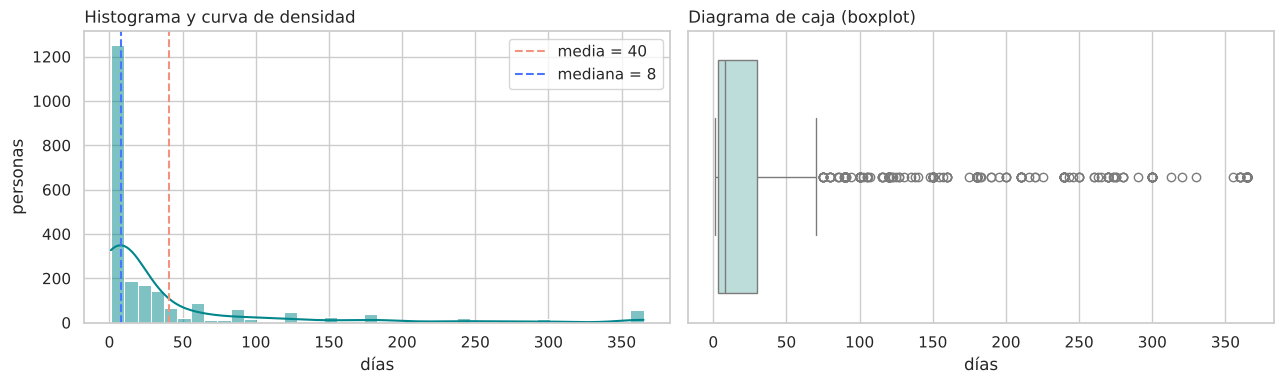

In [2]:
dias = encuesta[encuesta["ausencia"] == 1]["dias"].dropna()      # solo quien faltó

print("Personas que faltaron:", len(dias))
print("Media:", round(dias.mean(), 1), "días | Mediana:", round(dias.median(), 1), "días")
print("Asimetría:", round(dias.skew(), 1))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(dias, bins=40, kde=True, color=COLOR_PRINCIPAL, ax=ejes[0])
ejes[0].axvline(dias.mean(), color=COLOR_DESTACADO, linestyle="--", label="media = " + str(round(dias.mean())))
ejes[0].axvline(dias.median(), color="#4876FF", linestyle="--", label="mediana = " + str(round(dias.median())))
ejes[0].set_title("Histograma y curva de densidad", loc="left")
ejes[0].set_xlabel("días")
ejes[0].set_ylabel("personas")
ejes[0].legend()

sns.boxplot(x=dias, color=COLOR_SUAVE, ax=ejes[1])
ejes[1].set_title("Diagrama de caja (boxplot)", loc="left")
ejes[1].set_xlabel("días")
plt.tight_layout()
plt.show()

Evidencia que casi todo el mundo falta pocos días, pero unos pocos faltan mucho. La media queda muy por encima de la mediana, y la asimetría es muy positiva: una cola larga hacia la derecha. Por eso uso también la mediana, y por eso no quito los outliers: esas bajas largas son las que más me interesan.

---
## 7. Análisis bivariante

### H1 · ¿Cada vez hay más bajas?

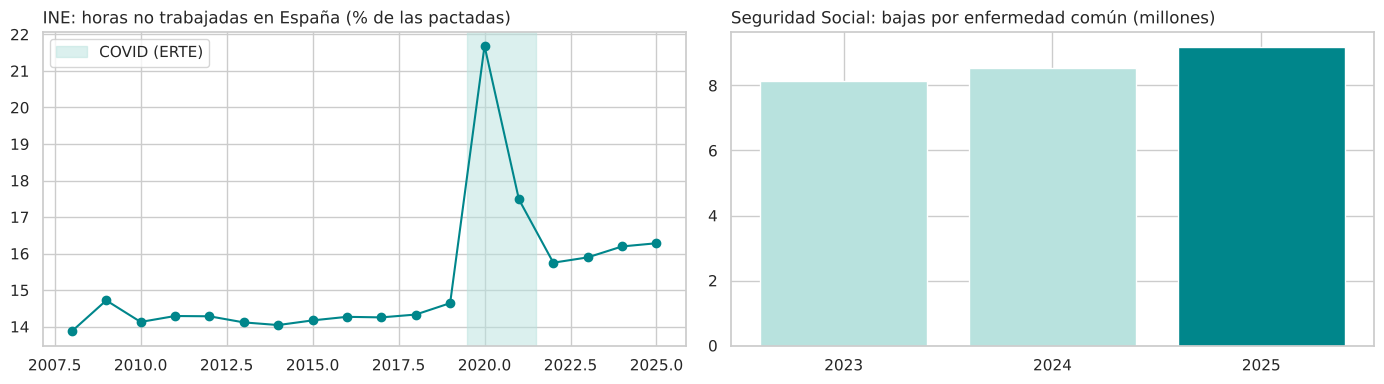

Bajas iniciadas: 8.15 millones en 2023 -> 9.2 millones en 2025 ( 12.8 % más )


In [3]:
# INE: media anual de España (solo años completos)
espana = ine[ine["codigo_ccaa"] == 0]
espana = espana[espana["sector"] == "Total"]
anual = espana.groupby("anio")["tasa_nt"].agg(["mean", "count"])
anual = anual[anual["count"] == 4]["mean"]

# Seguridad Social: bajas por enfermedad común iniciadas cada año
comunes = it_espana[it_espana["contingencia"] == "comunes"]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
ejes[0].plot(anual.index, anual.values, color=COLOR_PRINCIPAL, marker="o")
ejes[0].axvspan(2019.5, 2021.5, color=COLOR_SUAVE, alpha=0.5, label="COVID (ERTE)")
ejes[0].set_title("INE: horas no trabajadas en España (% de las pactadas)", loc="left")
ejes[0].legend()

ejes[1].bar(comunes["anio"].astype(str), comunes["iniciadas"] / 1000000, color=[COLOR_SUAVE, COLOR_SUAVE, COLOR_PRINCIPAL])
ejes[1].set_title("Seguridad Social: bajas por enfermedad común (millones)", loc="left")
plt.tight_layout()
plt.show()

subida = (comunes["iniciadas"].iloc[-1] / comunes["iniciadas"].iloc[0] - 1) * 100
print("Bajas iniciadas:", round(comunes["iniciadas"].iloc[0] / 1000000, 2), "millones en 2023 ->",
      round(comunes["iniciadas"].iloc[-1] / 1000000, 2), "millones en 2025 (", round(subida, 1), "% más )")

Evidencia que las horas no trabajadas estaban estables en torno al 14 % hasta 2019, se disparan con la COVID y en 2025 llegan al **16,3 %**, lo más alto sin contar la pandemia. Las bajas por enfermedad común pasan de **8,15 a 9,20 millones** en dos años: un **12,8 % más**. **SE CUMPLE**

### H2 · ¿Hay diferencias entre comunidades?

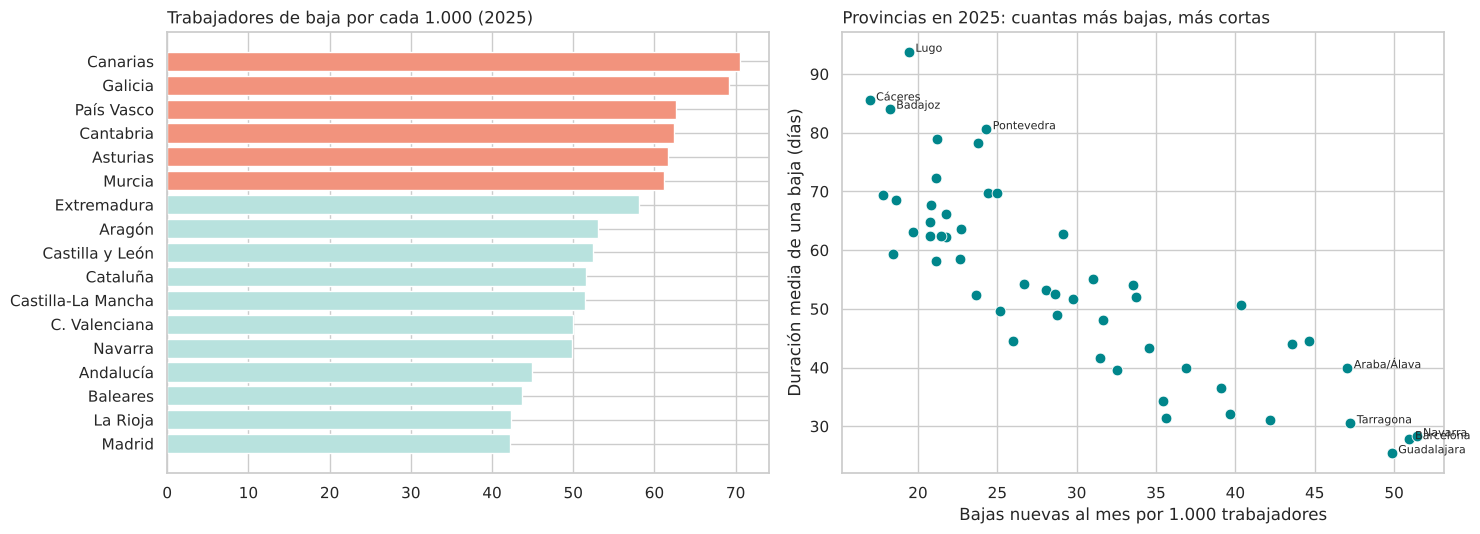

In [4]:
orden = comunidades.sort_values("prevalencia")
media = orden["prevalencia"].mean()
colores = []
for valor in orden["prevalencia"]:
    if valor > media + 5:
        colores.append(COLOR_DESTACADO)      # más de 5 puntos por encima de la media
    else:
        colores.append(COLOR_SUAVE)

it_2025 = it_provincias[it_provincias["anio"] == 2025]
it_2025 = it_2025[it_2025["contingencia"] == "comunes"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
ejes[0].barh(orden["ccaa"], orden["prevalencia"], color=colores)
ejes[0].set_title("Trabajadores de baja por cada 1.000 (2025)", loc="left")

sns.scatterplot(data=it_2025, x="incidencia", y="duracion", color=COLOR_PRINCIPAL, s=60, ax=ejes[1])
for numero_fila, fila in it_2025.iterrows():
    if fila["incidencia"] > 45 or fila["duracion"] > 80:                  # solo el nombre de las más extremas
        ejes[1].text(fila["incidencia"] + 0.4, fila["duracion"], fila["provincia"].title(), fontsize=8)
ejes[1].set_xlabel("Bajas nuevas al mes por 1.000 trabajadores")
ejes[1].set_ylabel("Duración media de una baja (días)")
ejes[1].set_title("Provincias en 2025: cuantas más bajas, más cortas", loc="left")
plt.tight_layout()
plt.show()

Evidencia que en Canarias y Galicia hay unos **70 trabajadores de baja por cada 1.000**; en Madrid, 42: **casi el doble**. 

A reseñar que: donde empiezan muchas bajas, duran poco (Navarra), y donde empiezan pocas, duran bastante (Lugo, más de tres meses). 

Esas bajas largas son las que más necesitan un plan de vuelta al trabajo. **SE CUMPLE**

### H3 · ¿Cómo se producen los accidentes y cuántos recaen?

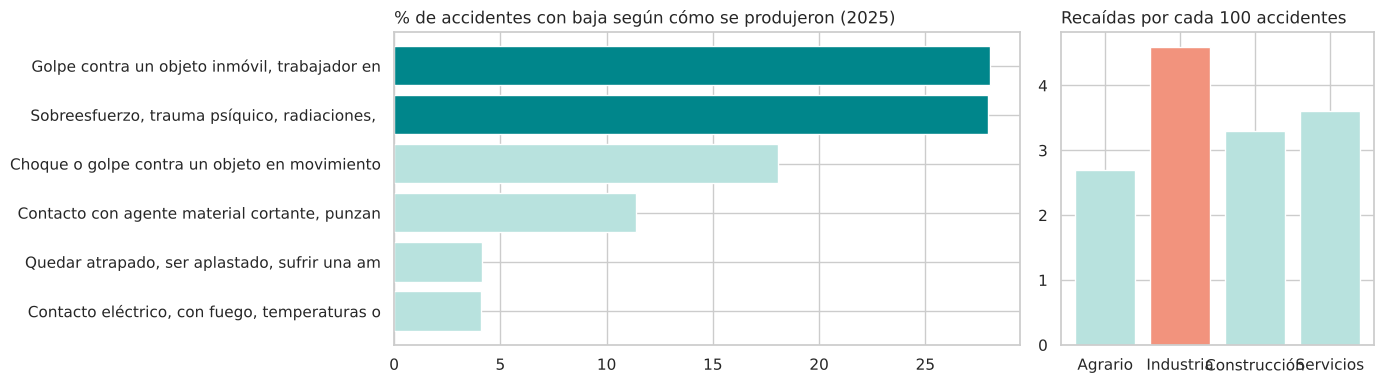

forma
Contacto eléctrico, con fuego, temperaturas o sustancias peligrosas     4.1
Quedar atrapado, ser aplastado, sufrir una amputación                   4.1
Contacto con agente material cortante, punzante, duro                  11.4
Choque o golpe contra un objeto en movimiento, colisión con            18.0
Sobreesfuerzo, trauma psíquico, radiaciones, ruido, etc.               28.0
Golpe contra un objeto inmóvil, trabajador en movimiento               28.1
Name: accidentes, dtype: float64


In [5]:
pct_forma = accidentes.groupby("forma")["accidentes"].sum() / accidentes["accidentes"].sum() * 100
pct_forma = pct_forma.sort_values().tail(6)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].barh(pct_forma.index.str[:45], pct_forma.values, color=[COLOR_SUAVE] * 4 + [COLOR_PRINCIPAL] * 2)
ejes[0].set_title("% de accidentes con baja según cómo se produjeron (2025)", loc="left")

colores = []
for sector in recaidas["sector"]:
    if sector == "Industria":
        colores.append(COLOR_DESTACADO)
    else:
        colores.append(COLOR_SUAVE)
ejes[1].bar(recaidas["sector"], recaidas["tasa_recaida"], color=colores)
ejes[1].set_title("Recaídas por cada 100 accidentes", loc="left")
plt.tight_layout()
plt.show()

print(pct_forma.round(1))

Evidencia que los sobreesfuerzos (28,0 %) **empatan** con los golpes contra objetos (28,1 %): no ganan solos. 

La **industria** es el sector donde más se recae (4,6 de cada 100 accidentes), justo lo que una buena reincorporación laboral puede evitar. **SE CUMPLE**

### H4 · ¿Los problemas de espalda y de salud mental hacen faltar más?

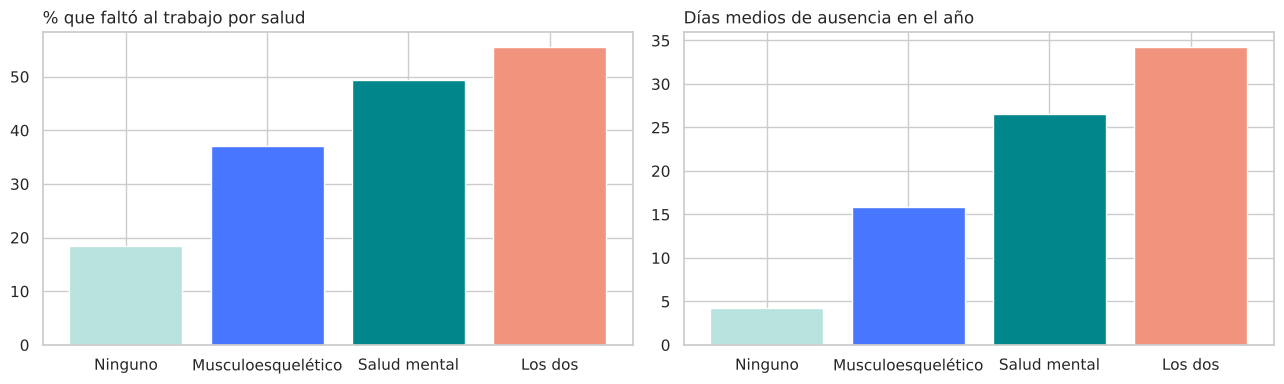

                grupo  % que faltó  días medios
0             Ninguno         18.4          4.3
1  Musculoesquelético         37.1         15.8
2        Salud mental         49.3         26.6
3             Los dos         55.6         34.3


In [6]:
orden_grupos = ["Ninguno", "Musculoesquelético", "Salud mental", "Los dos"]

pct_falta = []
dias_medios = []
for grupo in orden_grupos:
    datos = encuesta[encuesta["grupo_salud"] == grupo]
    pct_falta.append(round((datos["ausencia"] * datos["peso"]).sum() / datos["peso"].sum() * 100, 1))   # % ponderado
    datos = datos.dropna(subset=["dias"])
    dias_medios.append(round((datos["dias"] * datos["peso"]).sum() / datos["peso"].sum(), 1))          # media ponderada

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].bar(orden_grupos, pct_falta, color=COLORES_GRUPOS)
ejes[0].set_title("% que faltó al trabajo por salud", loc="left")
ejes[1].bar(orden_grupos, dias_medios, color=COLORES_GRUPOS)
ejes[1].set_title("Días medios de ausencia en el año", loc="left")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"grupo": orden_grupos, "% que faltó": pct_falta, "días medios": dias_medios}))

Evidencia que sin problemas de salud crónicos se falta de media **4 días** al año; con un problema musculoesquelético, 16; con salud mental, 27; y con **los dos a la vez, 34 días: ocho veces más**. Hay que mirar a la persona entera, no un diagnóstico suelto. **SE CUMPLE**

### H5 · ¿Una minoría se lleva la mayoría de los días?

El 1.6 % de los ocupados acumula el 50 % de los días (bajas de 150.0 días o más)


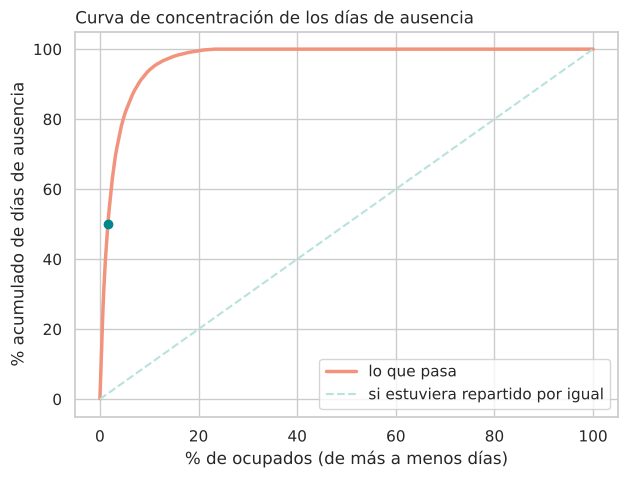

In [7]:
orden_dias = encuesta.dropna(subset=["dias"]).sort_values("dias", ascending=False).copy()
orden_dias["pct_personas"] = orden_dias["peso"].cumsum() / orden_dias["peso"].sum() * 100
orden_dias["pct_dias"] = (orden_dias["dias"] * orden_dias["peso"]).cumsum() / (orden_dias["dias"] * orden_dias["peso"]).sum() * 100

pct_mitad = orden_dias[orden_dias["pct_dias"] >= 50]["pct_personas"].iloc[0]      # la primera fila que llega al 50 % de los días
dias_umbral = orden_dias[orden_dias["pct_dias"] >= 50]["dias"].iloc[0]
print("El", round(pct_mitad, 1), "% de los ocupados acumula el 50 % de los días (bajas de", dias_umbral, "días o más)")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(orden_dias["pct_personas"], orden_dias["pct_dias"], color=COLOR_DESTACADO, linewidth=2.5, label="lo que pasa")
ax.plot([0, 100], [0, 100], color=COLOR_SUAVE, linestyle="--", label="si estuviera repartido por igual")
ax.scatter([pct_mitad], [50], color=COLOR_PRINCIPAL, zorder=3)
ax.set_xlabel("% de ocupados (de más a menos días)")
ax.set_ylabel("% acumulado de días de ausencia")
ax.set_title("Curva de concentración de los días de ausencia", loc="left")
ax.legend()
plt.show()

Evidencia que el **1,6 % de los ocupados** (bajas de 150 días o más) se lleva **la mitad** de todos los días de ausencia. En ese grupo la depresión es casi 6 veces más frecuente que en el resto y la artrosis casi 5. No hace falta actuar con todo el mundo, sino con muy pocas personas. **SE CUMPLE**

---
## 8. Análisis multivariante: la tabla común

La tabla común junta las cuatro fuentes en una fila por comunidad. Miro todas las medidas a la vez.

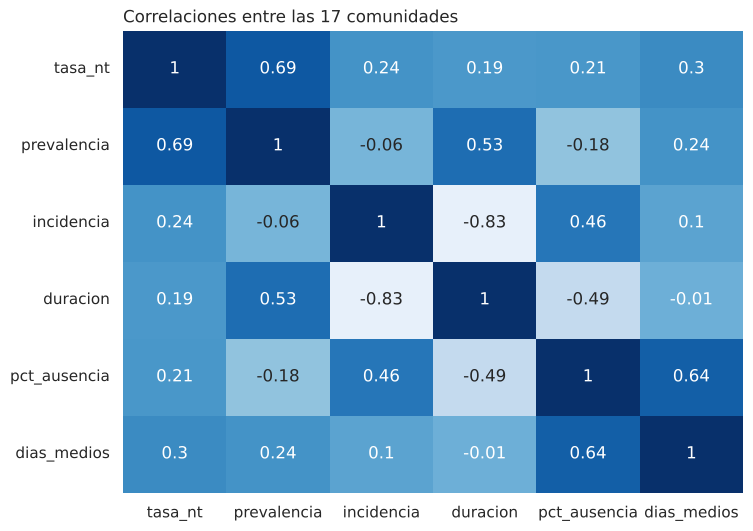

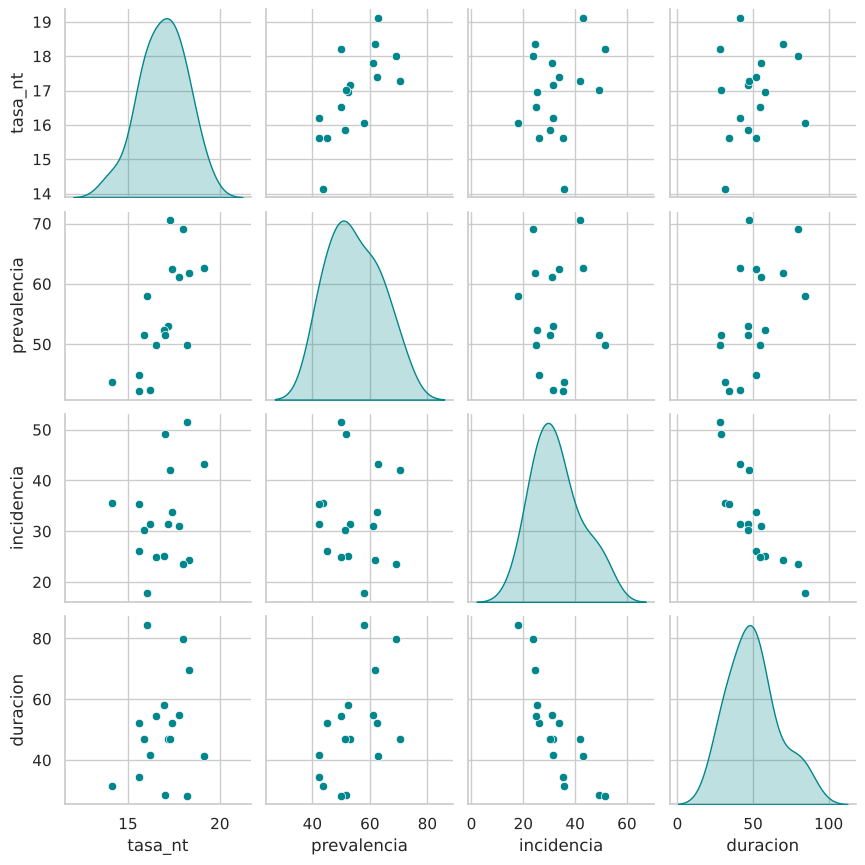

In [8]:
medidas = ["tasa_nt", "prevalencia", "incidencia", "duracion", "pct_ausencia", "dias_medios"]

plt.figure(figsize=(8, 6))
sns.heatmap(comunidades[medidas].corr().round(2), annot=True, fmt="g", cmap=MAPA_DE_CALOR, vmin=-1, vmax=1, cbar=False)
plt.title("Correlaciones entre las 17 comunidades", loc="left")
plt.show()

sns.pairplot(comunidades[["tasa_nt", "prevalencia", "incidencia", "duracion"]], diag_kind="kde", height=2.2,
             plot_kws={"color": COLOR_PRINCIPAL}, diag_kws={"color": COLOR_PRINCIPAL})
plt.show()

El INE y la Seguridad Social van juntos (0,69): donde hay más horas sin trabajar, hay más trabajadores de baja. 

La incidencia y la duración van al revés (−0,83): cuantas más bajas empiezan, menos duran. 

---
## 9. Contraste de hipótesis

Para cada hipótesis miro dos cosas: el **p-valor** (si es menor que 0,05, la diferencia no es casualidad) y el **tamaño del efecto** (si además importa). Ya que significativo no es lo mismo que importante.

In [9]:
# H1 · Pearson: ¿suben las horas no trabajadas con los años? (sin los años de la COVID)
desde_2015 = anual[anual.index >= 2015]
sin_covid = desde_2015.drop([2020, 2021])
r, p = stats.pearsonr(sin_covid.index, sin_covid.values)
print("H1 · Pearson año y horas no trabajadas (sin 2020-21): r =", round(r, 2), "| p =", round(p, 4))

# H1 · Wilcoxon: la misma provincia en 2023 y en 2025
provincias = it_provincias[it_provincias["contingencia"] == "comunes"].pivot(index="provincia", columns="anio", values="incidencia")
w, p = stats.wilcoxon(provincias[2023], provincias[2025])
suben = (provincias[2025] > provincias[2023]).sum()
print("H1 · Wilcoxon: suben", suben, "de", len(provincias), "provincias | p =", round(p, 4))

H1 · Pearson año y horas no trabajadas (sin 2020-21): r = 0.98 | p = 0.0
H1 · Wilcoxon: suben 49 de 52 provincias | p = 0.0


In [10]:
# H4 · Chi-cuadrado: ¿faltar al trabajo tiene que ver con cada problema de salud?
for problema in ["musculoesqueletico", "salud_mental"]:
    datos = encuesta.dropna(subset=["ausencia", problema])
    tabla = pd.crosstab(datos[problema], datos["ausencia"])
    chi2, p, grados_libertad, esperados = stats.chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    print("H4 · Chi-cuadrado faltar y", problema, "-> V de Cramér =", round(v_cramer, 2), "| p =", round(p, 4))

# H6 · Pearson entre las fuentes, por comunidad
r, p = stats.pearsonr(comunidades["tasa_nt"], comunidades["prevalencia"])
print("H6 · INE y Seguridad Social: r =", round(r, 2), "| p =", round(p, 3))
r, p = stats.pearsonr(comunidades["tasa_nt"], comunidades["pct_ausencia"])
print("H6 · INE y Encuesta: r =", round(r, 2), "| p =", round(p, 3))

# Extra · edad y días: significativo pero sin importancia
datos = encuesta.dropna(subset=["edad", "dias"])
r, p = stats.pearsonr(datos["edad"], datos["dias"])
print("Extra · Edad y días: r =", round(r, 2), "| p =", round(p, 4))

H4 · Chi-cuadrado faltar y musculoesqueletico -> V de Cramér = 0.21 | p = 0.0
H4 · Chi-cuadrado faltar y salud_mental -> V de Cramér = 0.21 | p = 0.0
H6 · INE y Seguridad Social: r = 0.69 | p = 0.002
H6 · INE y Encuesta: r = 0.21 | p = 0.421
Extra · Edad y días: r = 0.1 | p = 0.0


---
## 10. Conclusiones

1. **Cada vez hay más bajas:** 9,2 millones por enfermedad común en 2025, un 12,8 % más que en 2023, y **1 de cada 4 ocupados** faltó por salud en el último año.
2. **No pasa igual en todas partes:** casi el doble de trabajadores de baja en Canarias y Galicia que en Madrid. Y donde hay más bajas, son más cortas.
3. **Está muy concentrado:** el **1,6 %** de los ocupados se lleva **la mitad** de los días de ausencia.
4. **Tiene un perfil claro:** problemas musculoesqueléticos y de salud mental, muchas veces juntos (ocho veces más días que sin ninguno).
5. **La industria** es el sector con más horas no trabajadas y más recaídas.

## 11. Hay una oportunidad de intervención: del diagnóstico - al tratamiento

En la actualidad se actúa cuando la baja ya es larga. 

**Cuánto vale** (es un escenario, no una predicción): si quien repite baja genera el 64,5 % de los días (estudio del Ivie y Umivale Activa con datos de la Seguridad Social), reducir un poco sus días de baja ya supone mucho dinero.

In [11]:
gasto_millones = 18413          # gasto en bajas por enfermedad en 2025 (millones de euros)
peso_de_quien_repite = 0.645    # quien repite baja genera el 64,5 % de los días

ahorros = []
for reduccion in [0.05, 0.10, 0.20]:                                # 5 %, 10 % y 20 %
    ahorro = gasto_millones * peso_de_quien_repite * reduccion      # la cuenta
    ahorros.append(round(ahorro))

escenarios = pd.DataFrame({"Se reducen sus días de baja un": ["5 %", "10 %", "20 %"],
                           "Se ahorraría al año (millones de euros)": ahorros})
escenarios

,Se reducen sus días de baja un,Se ahorraría al año (millones de euros)
0,5 %,594
1,10 %,1188
2,20 %,2375


Con solo un **10 % menos** de días de baja de quien repite, el ahorro sería de unos **1.188 millones de euros al año**.

## 12. Limitaciones

- El INE, los accidentes y la Seguridad Social son datos agregados: dicen **dónde**, pero no **quién**.
- La encuesta es **autodeclarada** y no dice si la baja se repitió.
- Las relaciones son **asociaciones**, no causas. Los efectos son pequeños-moderados: las personas somos impredecibles y nadie falta por una sola causa.
- De la Seguridad Social solo hay datos comparables de 2023 a 2025, y sin sector.
- El ahorro es un **escenario** con un supuesto.

